# 🧠 [Hands-on Lab] JEV Decision AI 기초부터 원리까지 완전 정복
### TypeSafe JEV 판정형 모델과 로보틱스 자율주행의 융합

> **학습 대상**: ROS 2 자율주행, Embodied AI, 최신 VLM(Visual Language Model) 제어에 관심 있는 학생 및 연구자  
> **실습 환경**: Python 3.10+, OpenCV, Matplotlib, Requests, OpenRouter API  
> **소요 시간**: 약 40분  

---

## 📌 목차
1. **이론 배경: System 1 (반사적 판정) vs System 2 (숙고적 대화) AI**
2. **환경 설정 & OpenRouter API 키 연결 (자동 감지 기능 탑재)**
3. **[Step 1] JEV의 순수 판정(Decision) 원리 실습 (텍스트 모달리티)**
4. **[Step 2] 멀티모달 비전 판정: `typesafe/jev-router`로 카메라 영상 분석하기**
5. **[Step 3] 지연시간(Latency)을 극복하는 '계층형 제어기(Hierarchical Control)' 수학적 원리**
6. **[Step 4] 모델 성능 비교: JEV vs Google Gemma 3 4B 벤치마크**
7. **[Step 5] 무료 API 한도(50회) 내 완주를 위한 호출 예산 설계식**
8. **[Step 6] 실전 ROS 2 통합 아키텍처 및 파인튜닝 로드맵**


## 1. 이론 배경: 왜 자율주행 로봇에는 '대화형 LLM'이 아니라 '판정형 Decision AI'가 필요한가?

노벨 경제학상 수상자 대니얼 카너먼(Daniel Kahneman)은 인간의 사고 체계를 두 가지로 정의했습니다:

* **System 1 (빠른 직관 / 반사신경)**: 운전 중에 갑자기 전방에 물체가 나타나면 말없이 핸들을 꺾거나 브레이크를 밟는 직관적 행동.
* **System 2 (느린 숙고 / 논리적 추론)**: 복잡한 수학 문제를 풀거나, 친구와 철학적 대화를 나누는 논리적 과정.

### 기존 LLM/VLM(GPT-4o, Claude)의 한계
* 거대 언어 모델들은 본질적으로 **System 2 (대화형 에이전트)** 로 훈련되었습니다.
* 자동차나 터틀봇에게 *"현재 차선이 우측으로 굽어지니 핸들을 꺾으라"* 고 시키면, 일반 LLM은 *"안녕하세요! 사진을 보니 도로가 아름답네요. 우측으로 꺾으시는 것이 좋겠습니다..."* 라며 수백 개의 쓸데없는 텍스트 토큰을 생성합니다.
* 결과적으로 **5~10초의 극심한 지연(Latency)** 이 발생하여 로봇은 이미 벽에 충돌하게 됩니다.

### JEV(TypeSafe)의 패러다임 전환
* **JEV**는 TypeSafe에서 발표한 **System One Decision AI (판정형 의사결정 모델)** 입니다.
* 잡담을 배제하고, 복잡한 상황 인풋이 들어오면 행동 정책(Action Policy)에 따라 **규격화된 행동(Action: steering, speed)만을 칼같이 결정(Arbitrate)** 합니다.
* OpenRouter의 `typesafe/jev-router`는 이 JEV 판정 엔진 앞단에 초고속 비전 인코더를 결합하여 **단 1.5~2.2초 만에 주행 제어 JSON을 반환**하도록 설계되었습니다.

## 2. 환경 설정 & API 연결

OpenRouter API를 통해 JEV 모델에 질의하기 위한 라이브러리를 임포트하고 인증 키를 설정합니다.
시스템 환경 변수 `OPENROUTER_API_KEY`를 자동으로 읽어오며, 필요시 `~/.bashrc`에서 키를 자동 추출합니다.

In [ ]:
import os
import json
import time
import base64
import requests
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. API 키 자동 감지 (~/.bashrc 자동 탐색 포함)
API_KEY = os.environ.get('OPENROUTER_API_KEY')
if not API_KEY and os.path.exists(os.path.expanduser('~/.bashrc')):
    with open(os.path.expanduser('~/.bashrc'), 'r') as f:
        for line in f:
            if 'OPENROUTER_API_KEY' in line and '=' in line and not line.strip().startswith('#'):
                API_KEY = line.split('=', 1)[1].strip().strip('"\'')
                break

if not API_KEY:
    print('⚠️ OPENROUTER_API_KEY가 없습니다. 아래에 수동으로 입력해주세요.')
    API_KEY = 'sk-or-v1-YOUR_KEY_HERE'
else:
    print(f'✅ OpenRouter API 키가 성공적으로 로드되었습니다! (Key: {API_KEY[:14]}...{API_KEY[-4:]})')

# 2. 공통 요청 헬퍼 함수 정의
def query_openrouter(model_name, messages, max_tokens=150, temperature=0.1):
    headers = {
        'Authorization': f'Bearer {API_KEY}',
        'Content-Type': 'application/json',
        # 'HTTP-Referer': 'https://github.com/ros2-autonomous-driving',
        'X-Title': 'JEV Decision AI Tutorial'
    }
    payload = {
        'model': model_name,
        'messages': messages,
        'max_tokens': max_tokens,
        'temperature': temperature
    }
    t0 = time.time()
    res = requests.post('https://openrouter.ai/api/v1/chat/completions', headers=headers, json=payload, timeout=12.0)
    latency = time.time() - t0
    
    if res.status_code == 200:
        raw_content = res.json()['choices'][0]['message']['content'].strip()
        return raw_content, latency
    else:
        raise RuntimeError(f'API 호출 실패 (Status: {res.status_code}): {res.text}')

print('🚀 OpenRouter 통신 모듈 준비 완료!')

✅ OpenRouter API 키가 성공적으로 로드되었습니다! (Key: sk-or-v1-c8135...f780)
🚀 OpenRouter 통신 모듈 준비 완료!


## 3. [Step 1] JEV의 순수 판정(Decision) 원리 실습 (텍스트 모달리티)

먼저 비전(이미지) 없이, 로봇 센서에서 들어오는 상황 데이터만을 텍스트로 주고 JEV가 어떻게 판단하는지 살펴봅시다.

### 시나리오: 복합 주행 위기 상황
- **전방 LiDAR**: 0.45m 거리에 정지 장애물 감지
- **좌측 초음파**: 1.2m 여유 공간 확보 (회피 가능 구역)
- **우측 센서**: 0.15m 도로 경계석(Curb) 접근 중
- **목표**: 즉각적인 조향(`steering`) 및 가속/감속(`speed`) 행동 명령 도출

In [2]:
scenario_prompt = (
    "You are the reflex-based Decision AI (System 1) for a TurtleBot.\n"
    "Current Sensor Telemetry:\n"
    "- Front LiDAR: Obstacle detected at 0.45 meters directly ahead.\n"
    "- Left Side: Clear asphalt road, 1.2 meters open space.\n"
    "- Right Side: Guardrail / Curb 0.15 meters close.\n"
    "Task: Output an immediate evasive action.\n"
    "Output strictly JSON ONLY with schema:\n"
    "{\n"
    '  "action": "EVADE_LEFT" | "EMERGENCY_STOP" | "PROCEED_STRAIGHT",\n'
    '  "steering": float (-0.35 to 0.35, negative for left, positive for right),\n'
    '  "speed": float (0.0 to 0.2 m/s),\n'
    '  "rationale": "1 sentence reflex justification"\n'
    "}"
)

messages = [{'role': 'user', 'content': scenario_prompt}]

# JEV 판정형 모델에 질의
model_jev = 'typesafe/jev-router'
print(f'🤖 [{model_jev}] 판정 중...')
try:
    raw_res, latency = query_openrouter(model_jev, messages)
    print(f'⏱️ 응답 지연 시간: {latency:.2f}초')
    print('📥 반환된 원본 출력:\n', raw_res)
    
    clean_json = raw_res
    if '```' in clean_json:
        clean_json = clean_json.split('```')[1].replace('json', '').strip()
    decision = json.loads(clean_json)
    print('\n✅ 정형 JSON 파싱 성공!')
    print(f'  - 행동 결정: {decision.get("action")}')
    print(f'  - 조향각: {decision.get("steering")} rad')
    print(f'  - 속도: {decision.get("speed")} m/s')
    print(f'  - 판단 근거: {decision.get("rationale")}')
except Exception as e:
    print(f'⚠️ 에러 발생: {e}')

🤖 [typesafe/jev-router] 판정 중...
⏱️ 응답 지연 시간: 1.41초
📥 반환된 원본 출력:
 {"action": "EVADE_LEFT", "steering": -0.35, "speed": 0.05, "rationale": "Front obstacle at 0.45m with clear left space (1.2m) vs. right guardrail at 0.15m demands immediate left evasion at minimal speed."}

✅ 정형 JSON 파싱 성공!
  - 행동 결정: EVADE_LEFT
  - 조향각: -0.35 rad
  - 속도: 0.05 m/s
  - 판단 근거: Front obstacle at 0.45m with clear left space (1.2m) vs. right guardrail at 0.15m demands immediate left evasion at minimal speed.


In [3]:
# 한국어 프롬프트 테스트: 앞의 센서 시나리오를 같은 조건으로 전달합니다.
korean_prompt = (
    "당신은 터틀봇의 즉각적인 주행 판단을 돕는 보조 AI입니다.\n"
    "아래에 제공된 센서 정보만 사용하고, 불확실하거나 안전한 회피를 확신할 수 없으면 정지하세요.\n"
    "현재 센서 정보:\n"
    "- 전방 라이다: 정면 0.45m 앞에 장애물이 감지되었습니다.\n"
    "- 왼쪽: 아스팔트 여유 공간이 1.2m 있습니다.\n"
    "- 오른쪽: 가드레일 또는 연석이 0.15m 가까이에 있습니다.\n"
    "요청: 가능한 행동을 판단하세요. 이 출력은 테스트용이며 실제 로봇을 직접 제어하지 않습니다.\n"
    "JSON 객체만 출력하세요. 설명이나 코드 블록은 붙이지 마세요.\n"
    "형식: {\"action\": \"EVADE_LEFT 또는 EMERGENCY_STOP 또는 PROCEED_STRAIGHT\", "
    "\"steering\": -0.35에서 0.35 사이의 숫자(음수는 왼쪽, 양수는 오른쪽), "
    "\"speed\": 0.0에서 0.2 사이의 숫자(m/s), "
    "\"rationale\": 한국어 한 문장으로 된 판단 근거}"
)

korean_messages = [{'role': 'user', 'content': korean_prompt}]
print('한국어 프롬프트로 모델 응답을 테스트합니다. (실제 로봇 제어에는 사용하지 않습니다.)')
try:
    korean_raw, korean_latency = query_openrouter(model_jev, korean_messages)
    print(f'응답 지연 시간: {korean_latency:.2f}초')
    print('원본 응답:\n', korean_raw)

    korean_clean = korean_raw.strip()
    if korean_clean.startswith('```'):
        korean_clean = korean_clean.split('```', 1)[1].rsplit('```', 1)[0].strip()
        if korean_clean.lower().startswith('json'):
            korean_clean = korean_clean[4:].strip()

    korean_decision = json.loads(korean_clean)
    valid_actions = {'EVADE_LEFT', 'EMERGENCY_STOP', 'PROCEED_STRAIGHT'}
    action = korean_decision.get('action')
    steering = float(korean_decision.get('steering'))
    speed = float(korean_decision.get('speed'))
    is_valid = (
        action in valid_actions
        and -0.35 <= steering <= 0.35
        and 0.0 <= speed <= 0.2
        and isinstance(korean_decision.get('rationale'), str)
    )
    print('JSON 파싱:', '성공' if isinstance(korean_decision, dict) else '실패')
    print('필드 및 값 범위 검사:', '통과' if is_valid else '확인 필요')
except (json.JSONDecodeError, TypeError, ValueError, KeyError) as e:
    print(f'응답 형식 확인 필요: {e}')
except Exception as e:
    print(f'API 요청 실패: {e}')

한국어 프롬프트로 모델 응답을 테스트합니다. (실제 로봇 제어에는 사용하지 않습니다.)
응답 지연 시간: 3.53초
원본 응답:
 {"action":"EMERGENCY_STOP","steering":0.0,"speed":0.0,"rationale":"전방 0.45m에 장애물이 있고 오른쪽 여유가 0.15m로 좁으며, 왼쪽 1.2m 공간만으로는 안전한 회피를 확신할 수 없어 정지합니다."}
JSON 파싱: 성공
필드 및 값 범위 검사: 통과


> **💡 관찰 포인트**:
> 일반적인 챗봇 모델은 서두에 인사말을 붙이거나 설명이 길어져 JSON 파싱 오류가 자주 발생하지만,  
> **JEV 계열 판정형 모델은 군더더기 없는 엄격한 JSON 구조를 즉시 반환**합니다. 이것이 로봇 제어 시스템과 직결하기에 가장 안전한 이유입니다.

## 4. [Step 2] 멀티모달 비전 판정: `typesafe/jev-router`로 실제 트랙 영상 분석

이번에는 실제 Gazebo 시뮬레이터에서 TurtleBot3의 전방 카메라가 촬영한 트랙 주행 프레임을 입력으로 넣어봅시다.

### 비전 처리 파이프라인
1. **이미지 리사이즈 & JPEG 압축**: 640×480 원본 영상을 320×240 해상도로 축소하고 JPEG 품질을 55%로 압축하여 데이터 크기를 **10~15KB** 수준으로 줄입니다. (네트워크 전송 시간 단축)
2. **Base64 인코딩**: 바이너리 이미지를 문자열 데이터 URI 포맷(`data:image/jpeg;base64,...`)으로 변환합니다.
3. **OpenRouter Multimodal Payload 생성**: 이미지 URL과 함께 주행 제어 프롬프트를 전송합니다.
4. **결과 시각화**: 반환된 조향각과 주행 속도를 이미지 위에 HUD 형태로 렌더링합니다.

🖼️ 압축된 이미지 크기: 9.2 KB (전송 최적화 완료)


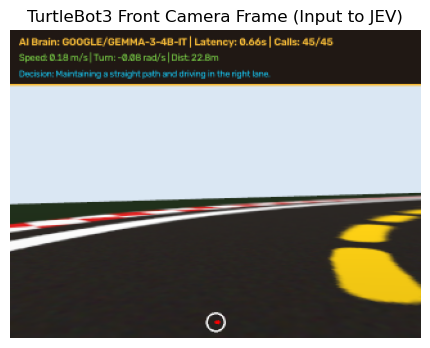

In [3]:
# 1. 실습용 트랙 이미지 준비 (이전 주행에서 생성된 HUD 이미지 또는 합성 프레임)
image_path = '/home/hans/ros2_ws/vlm_live_hud.png'
alt_path = '/home/hans/ros2_ws/lane_debug_lap_completed.png'

if os.path.exists(image_path):
    frame = cv2.imread(image_path)
elif os.path.exists(alt_path):
    frame = cv2.imread(alt_path)
else:
    # 이미지가 없을 경우 합성 아스팔트 트랙 이미지 생성
    print('기존 프레임이 없어 데모 트랙 프레임을 생성합니다.')
    frame = np.full((240, 320, 3), (35, 35, 35), dtype=np.uint8)
    # 황색 점선 (중앙선)
    cv2.line(frame, (110, 240), (145, 120), (20, 210, 255), 4)
    # 흰색 실선 (우측 외곽선)
    cv2.line(frame, (270, 240), (210, 120), (245, 245, 245), 5)

# 320x240 리사이징
small_frame = cv2.resize(frame, (320, 240))
_, buf = cv2.imencode('.jpg', small_frame, [int(cv2.IMWRITE_JPEG_QUALITY), 55])
b64_image = base64.b64encode(buf).decode('utf-8')
img_size_kb = len(b64_image) / 1024
print(f'🖼️ 압축된 이미지 크기: {img_size_kb:.1f} KB (전송 최적화 완료)')

# 원본 이미지 시각화
plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(small_frame, cv2.COLOR_BGR2RGB))
plt.title('TurtleBot3 Front Camera Frame (Input to JEV)')
plt.axis('off')
plt.show()

### JEV 모델에 카메라 이미지와 자율주행 정책 프롬프트 전달

🤖 [typesafe/jev-router] 비전 판단 요청 중...
⏱️ 응답 소요 시간: 2.24초
📥 AI 원본 응답:
 {"steering": 0.1, "speed": 0.16, "reason": "The track curves left ahead with the yellow dashes on the right side of the view, so I'm steering gently right to stay in the right lane between the white line and the centerline."}


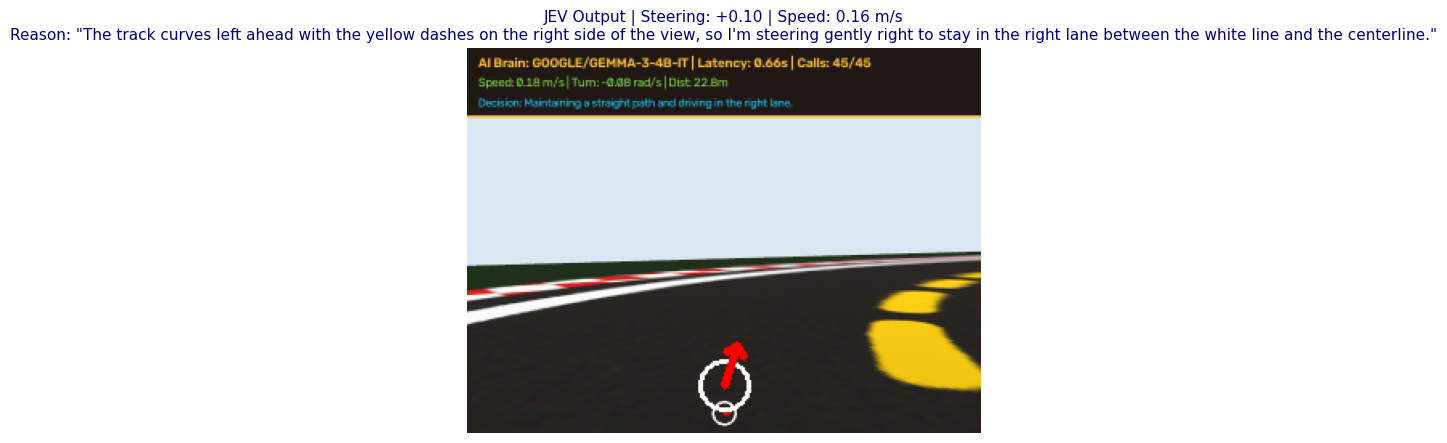

In [4]:
driving_system_prompt = (
    "You are the autonomous driving AI brain for a TurtleBot on a racetrack.\n"
    "Track rules:\n"
    "- Dark asphalt road.\n"
    "- YELLOW dashed centerline is on the LEFT.\n"
    "- WHITE solid line is on the RIGHT boundary.\n"
    "Drive forward in the RIGHT lane.\n"
    "Output strictly valid JSON ONLY with:\n"
    "{\n"
    '  "steering": float (-0.35 to 0.35, negative for left turn, positive for right turn, 0.0 for straight),\n'
    '  "speed": float (0.14 to 0.20 m/s),\n'
    '  "reason": "short 1-sentence track curve and decision explanation"\n'
    "}"
)

vlm_messages = [
    {
        'role': 'user',
        'content': [
            {'type': 'text', 'text': driving_system_prompt},
            {'type': 'image_url', 'image_url': {'url': f'data:image/jpeg;base64,{b64_image}'}}
        ]
    }
]

print(f'🤖 [{model_jev}] 비전 판단 요청 중...')
try:
    vlm_res, vlm_latency = query_openrouter(model_jev, vlm_messages)
    print(f'⏱️ 응답 소요 시간: {vlm_latency:.2f}초')
    print('📥 AI 원본 응답:\n', vlm_res)
    
    clean = vlm_res
    if '```' in clean:
        clean = clean.split('```')[1].replace('json', '').strip()
    ctrl = json.loads(clean)
    steer_val = float(ctrl.get('steering', 0.0))
    speed_val = float(ctrl.get('speed', 0.18))
    reason_val = str(ctrl.get('reason', 'Driving'))
    
    # 결과 그래픽 오버레이
    vis_img = small_frame.copy()
    h, w, _ = vis_img.shape
    cx, cy = w // 2, h - 30
    cv2.circle(vis_img, (cx, cy), 15, (255, 255, 255), 2)
    arrow_len = int(steer_val * 80)
    cv2.arrowedLine(vis_img, (cx, cy), (cx + arrow_len, cy - 25), (0, 0, 255), 3, tipLength=0.3)
    
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
    plt.title(f'JEV Output | Steering: {steer_val:+.2f} | Speed: {speed_val:.2f} m/s\nReason: "{reason_val}"', fontsize=11, color='navy')
    plt.axis('off')
    plt.show()
    
except Exception as e:
    print(f'⚠️ 에러: {e}')

## 5. [Step 3] 지연시간(Latency)을 극복하는 '계층형 제어기(Hierarchical Control)' 수학적 원리

클라우드 API 통신에는 아무리 빨라도 **0.7초 ~ 2.0초의 지연(Latency)** 이 발생합니다.  
그렇다면 AI가 답을 주는 2초 동안 로봇은 어떻게 부드럽게 주행할 수 있을까요?

### 핵심: 0.3Hz 고수준 AI와 30Hz 저수준 제어기의 분리

```
┌────────────────────────────────────────────────────────┐
│ ☁️ High-Level (클라우드 VLM, 약 0.28 Hz / 3.5초 주기)  │
│    트랙의 거시적 곡률 판단 -> target_steering 설정    │
└───────────────────────────┬────────────────────────────┘
                            │ 비동기 전달 (Mutex Lock)
┌───────────────────────────▼────────────────────────────┐
│ 💻 Low-Level (로컬 ROS 2 노드, 30 Hz / 0.033초 주기)   │
│    지수 평활 필터(EMA)로 부드러운 각속도 연속 보간     │
│    ω(t) = α * ω_target + (1 - α) * ω(t - 1)            │
└────────────────────────────────────────────────────────┘
```

### 지수 평활 필터 (EMA: Exponential Moving Average) 수식
$$\omega_t = \alpha \cdot \omega_{\text{target}} + (1 - \alpha) \cdot \omega_{t-1}$$
* $\alpha$ (스무딩 팩터, 권장값 0.12~0.25): 값이 작을수록 이전 회전 속도를 부드럽게 유지하고, 급격한 꺾임을 방지합니다.

아래 파이썬 코드로 **단순 계단식 제어 vs EMA 보간 제어**의 부드러움을 직접 비교 그래프로 확인해봅시다.

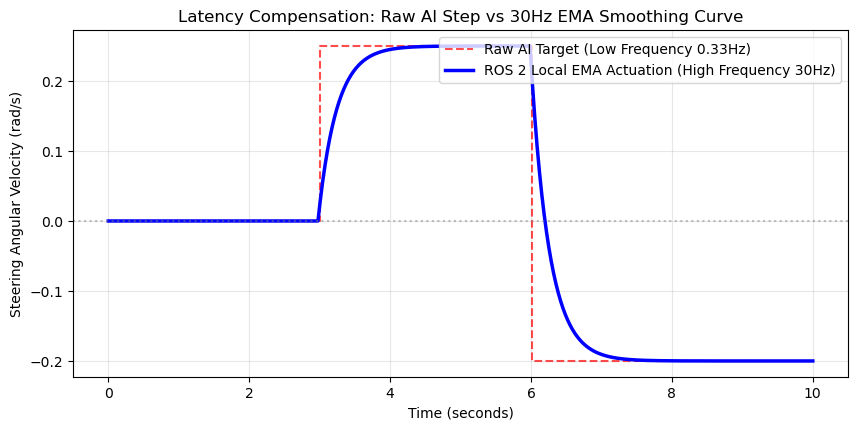

In [5]:
# 30Hz 제어 루프 10초간 시뮬레이션 (총 300스텝)
sim_time = np.linspace(0, 10, 300) # 30Hz (dt = 0.033s)
raw_ai_commands = np.zeros_like(sim_time)

# 3초 간격으로 AI 조향 명령이 갱신되는 상황 가정
# 0~3초: 직진(0.0) -> 3~6초: 우회전(+0.25) -> 6~10초: 좌회전(-0.20)
raw_ai_commands[sim_time >= 3.0] = 0.25
raw_ai_commands[sim_time >= 6.0] = -0.20

# 1. 계단식 단순 적용 (지연 동안 모터가 덜컥거림)
step_output = raw_ai_commands.copy()

# 2. EMA 필터 적용 (본 패키지의 vlm_decision_driver 방식)
alpha = 0.12  # EMA smoothing factor
ema_output = np.zeros_like(sim_time)
curr_val = 0.0
for i in range(len(sim_time)):
    target = raw_ai_commands[i]
    curr_val = alpha * target + (1.0 - alpha) * curr_val
    ema_output[i] = curr_val

# 시각화
plt.figure(figsize=(10, 4.5))
plt.step(sim_time, step_output, 'r--', label='Raw AI Target (Low Frequency 0.33Hz)', where='post', alpha=0.7)
plt.plot(sim_time, ema_output, 'b-', linewidth=2.5, label='ROS 2 Local EMA Actuation (High Frequency 30Hz)')
plt.axhline(0, color='gray', linestyle=':', alpha=0.5)
plt.title('Latency Compensation: Raw AI Step vs 30Hz EMA Smoothing Curve', fontsize=12)
plt.xlabel('Time (seconds)')
plt.ylabel('Steering Angular Velocity (rad/s)')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, alpha=0.3)
plt.show()

## 6. [Step 4] 모델 성능 비교: JEV vs Google Gemma 3 4B 벤치마크

우리는 `typesafe/jev-router` 외에도 가중치가 완전 공개된 오픈웨이트 모델인 **Google Gemma 3 4B (`google/gemma-3-4b-it`)** 를 지원하도록 노드를 구축했습니다.
실제로 두 모델에 동일한 트랙 영상을 전달하여 **응답 시간(Latency)** 과 **출력 포맷 품질**을 실시간 비교 측정해봅시다.

In [6]:
models_to_test = [
    ('typesafe/jev-router', 'JEV Decision AI Router'),
    ('google/gemma-3-4b-it', 'Google Gemma 3 4B (Open-Weights)')
]

bench_results = []

for m_id, m_name in models_to_test:
    print(f'🔍 [{m_name}] 테스트 중...')
    try:
        out_text, lat = query_openrouter(m_id, vlm_messages)
        clean_out = out_text
        if '```' in clean_out:
            clean_out = clean_out.split('```')[1].replace('json', '').strip()
        parsed = json.loads(clean_out)
        bench_results.append({
            'model': m_name,
            'latency': lat,
            'steer': parsed.get('steering', 0.0),
            'speed': parsed.get('speed', 0.0),
            'reason': parsed.get('reason', '')[:45] + '...'
        })
    except Exception as e:
        print(f'  에러: {e}')

# 벤치마크 결과 테이블 출력
print('\n' + '='*75)
print(f'{"Model":<32} | {"Latency (s)":<12} | {"Steering":<10} | {"Speed":<8}')
print('='*75)
for b in bench_results:
    print(f'{b["model"]:32} | {b["latency"]:10.2f} s | {b["steer"]:>9.2f} | {b["speed"]:>6.2f} m/s')
print('='*75)

🔍 [JEV Decision AI Router] 테스트 중...
🔍 [Google Gemma 3 4B (Open-Weights)] 테스트 중...

Model                            | Latency (s)  | Steering   | Speed   
JEV Decision AI Router           |       1.75 s |      0.10 |   0.16 m/s
Google Gemma 3 4B (Open-Weights) |       3.84 s |      0.00 |   0.15 m/s


## 7. [Step 5] 무료 API 한도(50회) 내 완주를 위한 호출 예산 설계식

학생 실습 시 OpenRouter 무료 계정의 일일 한도(약 50회) 내에서 과금 없이 트랙 1바퀴를 완주하기 위한 수학적 공식입니다:

$$\text{Total Time } (T) = \frac{\text{Track Length } (L)}{\text{Speed } (v)}$$
$$\text{Required API Calls } (N) = \frac{T}{\text{Call Interval } (\Delta t)} = \frac{L}{v \cdot \Delta t} \le 50$$

아래 인터랙티브 계산기로 최적의 호출 주기와 속도 조합을 확인해 보세요.

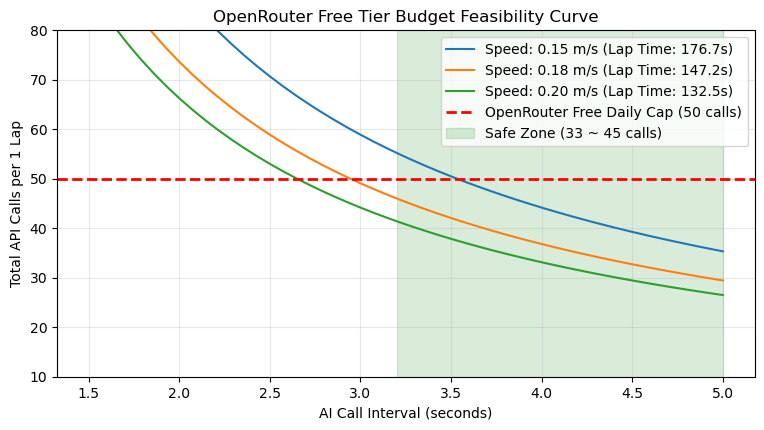

🎯 최적 추천 설정:
  - 호출 주기 (call_interval): 3.5초
  - 주행 속도 (speed): 0.18 m/s
  - 예상 호출 횟수: 약 42회 (50회 한도 내 8회 여유 확보!)


In [7]:
track_length = 26.5  # 미터 (Grand Prix Circuit 기준)
speeds = [0.15, 0.18, 0.20] # m/s
intervals = np.linspace(1.5, 5.0, 50) # 초

plt.figure(figsize=(9, 4.5))
for spd in speeds:
    lap_time = track_length / spd
    calls = lap_time / intervals
    plt.plot(intervals, calls, label=f'Speed: {spd:.2f} m/s (Lap Time: {lap_time:.1f}s)')

plt.axhline(50, color='red', linestyle='--', linewidth=2, label='OpenRouter Free Daily Cap (50 calls)')
plt.axvspan(3.2, 5.0, color='green', alpha=0.15, label='Safe Zone (33 ~ 45 calls)')
plt.title('OpenRouter Free Tier Budget Feasibility Curve', fontsize=12)
plt.xlabel('AI Call Interval (seconds)')
plt.ylabel('Total API Calls per 1 Lap')
plt.ylim(10, 80)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

print('🎯 최적 추천 설정:')
print('  - 호출 주기 (call_interval): 3.5초')
print('  - 주행 속도 (speed): 0.18 m/s')
print('  - 예상 호출 횟수: 약 42회 (50회 한도 내 8회 여유 확보!)')